In [11]:
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import Dataset, DataLoader
from ml.data import QuantumJumpDataset
from ml.loss import MSLELoss, RMSELoss


class DeepSet(nn.Module):
    def __init__(
        self,
        input_dim: int,
        output_dim: int,
        hidden_dims_phi: list[int] = [64, 64, 64],
        hidden_dims_rho: list[int] = [64, 32, 16],
        phi_activation: nn.Module = nn.ReLU,
        rho_activation: nn.Module = nn.ReLU,
        dropout: float = 0.0,
    ):
        """
        Args:
            input_dim: Dimension of each *element* in the set.
            output_dim: Dimension of the output.
            hidden_dims_rho: Hidden dimensions for the rho mapping.
            hidden_dims_phi: Hidden dimensions for the phi mapping.
            phi_activation: Activation function for phi layers.
            rho_activation: Activation function for rho layers.
            dropout: Dropout rate to apply after each layer.

        """
        super().__init__()

        # phi maps each element x ∈ X
        # For some reason using BatchNorm layer messes up phi network
        phi_layers = [
            nn.Linear(input_dim, hidden_dims_phi[0]),
            phi_activation(),
            # nn.Dropout(p=dropout),
        ]

        for i in range(len(hidden_dims_phi) - 1):
            phi_layers.extend(
                [
                    nn.Linear(hidden_dims_phi[i], hidden_dims_phi[i + 1]),
                    phi_activation(),
                    # nn.Dropout(p=dropout),
                ]
            )

        phi_layers.append(nn.Linear(hidden_dims_phi[-1], hidden_dims_phi[-1]))
        self.phi = nn.Sequential(*phi_layers)

        # rho maps the sum of phi(x_i)
        rho_layers = [
            nn.Linear(hidden_dims_phi[-1], hidden_dims_rho[0]),
            rho_activation(),
            # nn.BatchNorm1d(hidden_dims_rho[0]),
            nn.Dropout(p=dropout),
        ]

        for i in range(len(hidden_dims_rho) - 1):
            rho_layers.extend(
                [
                    nn.Linear(hidden_dims_rho[i], hidden_dims_rho[i + 1]),
                    rho_activation(),
                    # nn.BatchNorm1d(hidden_dims_rho[i + 1]),
                    nn.Dropout(p=dropout),
                ]
            )

        rho_layers.append(nn.Linear(hidden_dims_rho[-1], output_dim))
        self.rho = nn.Sequential(*rho_layers)

    def forward(self, x: torch.Tensor):
        """
        Args:
        x: input tensor of shape (batch_size, set_size, input_dim) where
                `input_dim` is the dimension of each *element* in the set 
                e.g. in the two-level system these are scalars so it is 1.
                `set_size` is the number of elements in the set, e.g. number of jumps.
                `batch_size` is the number of sets in the batch, e.g. number of trajectories.
        """
        x = self.phi(x)  # shape: (batch_size, set_size, hidden_dim)
        # sum over set elements -> (batch_size, hidden_dim)
        # add up phi representations of each element in the set
        x = x.sum(dim=1)  
        out = self.rho(x)  # final output
        return out


In [12]:
train_set_size = 320_000  # Adjust as needed
X_train = np.load("../train_val_data/estimation_data/train/1D/taus.npy")[
    :train_set_size
]

# make each element in a trajectory a 1D tensor for deep set network
X_train = np.expand_dims(X_train, axis=-1)

y_train = np.load("../train_val_data/estimation_data/train/1D/deltas.npy").reshape(
    -1, 1
)[:train_set_size]


train_dataset = QuantumJumpDataset(X_train, y_train, transform=False)


In [15]:
train_dataset.data.shape

torch.Size([320000, 48, 1])

In [ ]:
def train_deepset():
    # Hyperparameters
    hidden_dim = 64
    num_epochs = 250
    batch_size = 256 # seems like lower batch size works better for generalization (known fact actually)
    lr = 1e-4

    # Model, loss, optimizer
    model = DeepSet(
        input_dim=train_dataset[0][0].shape[1], output_dim=train_dataset[0][1].shape[0]
    )

    print(model)

    loss_fn = RMSELoss()  # nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    # Data
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

    # Training loop
    for epoch in range(num_epochs):
        model.train()
        model = model.to("cuda")  # Move model to GPU if available
        total_loss = 0
        for batch_x, batch_y in train_loader:
            batch_x = batch_x.to("cuda", non_blocking=True)
            batch_y = batch_y.to("cuda", non_blocking=True)
            optimizer.zero_grad()
            pred = model(batch_x)
            loss = loss_fn(pred, batch_y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * batch_x.size(0)

        print(f"Epoch {epoch + 1}, Loss: {total_loss / len(train_loader.dataset)}")

    return model

In [4]:
model = train_deepset()

DeepSet(
  (phi): Sequential(
    (0): Linear(in_features=1, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=64, bias=True)
  )
  (rho): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.0, inplace=False)
    (9): Linear(in_features=16, out_features=1, bias=True)
  )
)
Epoch 1, Loss: 0.4919292605638504
Epoch 2, Loss: 0.28206566429138186
Epoch 3, Loss: 0.27277386575937274
Epoch 4, Loss: 0.2664457733988762
Epoch 5, Loss: 0.25705065977573394
Epoch 6, Loss: 0.23807150317430495
Epoch 7, Loss: 0.23347508524656296
Epoch

In [5]:
from torch import from_numpy

device = "cuda"

X_test = np.load(
    "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
)
X_test = np.expand_dims(
    X_test, axis=-1
)  # make each element in a trajectory a 1D tensor for deep set network
y_test = np.load(
    "../test-trajectories/1D-delta/validation-deltas-1D-delta-nsets-10000.npy"
).reshape(-1, 1)

X_test = from_numpy(X_test).float().to(device)
y_test = from_numpy(y_test).float().to(device)

print(f"Shape of test data: {X_test.shape}.")
print(f"Shape of test labels: {y_test.shape}.")

Shape of test data: torch.Size([40, 10000, 48, 1]).
Shape of test labels: torch.Size([40, 1]).


In [6]:
from torch import mean, repeat_interleave

rmses = []
biases = []
model.eval()
model = model.to(device)
rmse_loss = RMSELoss()

with torch.no_grad():
    for trajectories, delta in zip(X_test, y_test):
        batch_output = model(trajectories)
        mean_output = mean(batch_output, dim=0).cpu().item()
        biases.append(mean_output - delta.cpu())
        labels = repeat_interleave(delta, repeats=batch_output.shape[0]).reshape(-1, 1)

        rmse = rmse_loss(batch_output, labels)

        rmses.append(rmse.cpu().numpy())


In [7]:
import matplotlib.pyplot as plt

from scipy.interpolate import CubicSpline
from scipy import signal

def get_derivative(x,y):
    yfilt = signal.savgol_filter(y,7,3) 
    xFine = np.linspace(np.min(x), np.max(x), len(x))
    yfun = CubicSpline(x,yfilt)
    yFine= yfun(xFine)
    derYFine = np.gradient(yFine,xFine)
    derYfun = CubicSpline(xFine,derYFine)
    derY = derYfun(x)
    return derY


# derBiasBayes = get_derivative(deltalist,biasBayes)

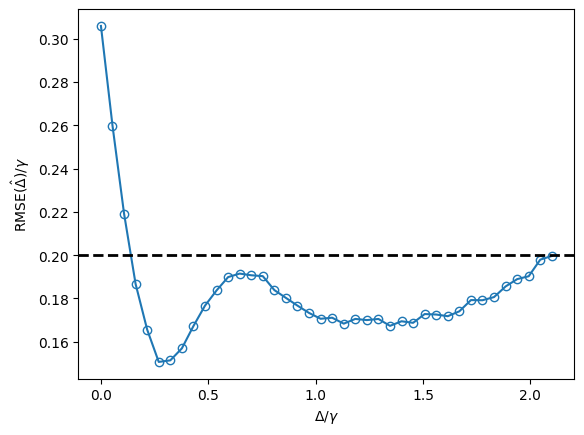

In [8]:
plt.plot(
    y_test.cpu().numpy().flatten(),
    rmses,
    marker="o",
    markerfacecolor="none",
    linestyle="-",
)
# plt.xlim([0, 0.5])
# plt.ylim([0, 0.25])
plt.axhline(
    y=0.2, color="black", linestyle="--", linewidth=2
) 
plt.xlabel(r"$\Delta/\gamma$")
plt.ylabel(r"RMSE$(\hat{\Delta})/\gamma$");

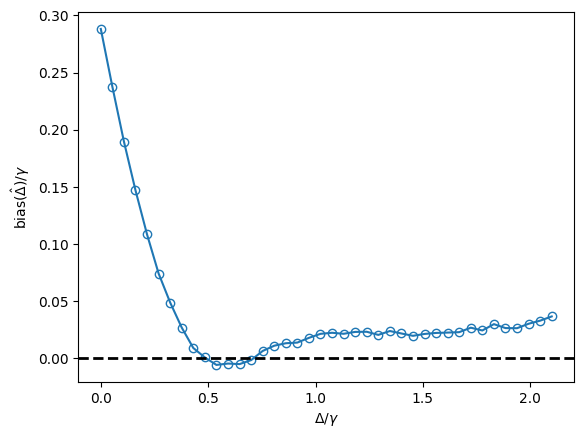

In [9]:
plt.plot(
    y_test.cpu().numpy().flatten(),
    biases,
    marker="o",
    markerfacecolor="none",
    linestyle="-",
)
plt.axhline(
    y=0, color="black", linestyle="--", linewidth=2
)  # horizontal line at bias = 0

plt.xlabel(r"$\Delta/\gamma$")
plt.ylabel(r"bias$(\hat{\Delta})/\gamma$");